# SalesInsight PY
Análise e visualização de dados de vendas com Python.

## RF01 - Criar ou carregar o dataset de vendas

In [1]:
import pandas as pd
import numpy as np
import random
from datetime import datetime, timedelta

In [2]:
def gerar_dataset_vendas(n_registros=200, seed=42):
    """Gera um dataset sintético de vendas com dados sujos."""

    random.seed(seed)
    np.random.seed(seed)

    produtos = ["Notebook", "Smartphone", "Tablet", "Monitor", "Teclado", "Mouse", "Headset"]

    categorias = {
    "Notebook": "Computadores",
    "Smartphone": "Celulares",
    "Tablet": "Celulares",
    "Monitor": "Computadores",
    "Teclado": "Perifericos",
    "Mouse": "Perifericos",
    "Headset": "Perifericos"}

    precos = {
    "Notebook": 3500,
    "Smartphone": 2200,
    "Tablet": 1800,
    "Monitor": 1200,
    "Teclado": 250,
    "Mouse": 120,
    "Headset": 350}

    regioes = ["Sudeste", "Sul", "Nordeste", "Centro-Oeste", "Norte"    ]

    data_inicio = datetime(2025, 1, 1)
    dados = []

    for i in range(n_registros):
        produto = random.choice(produtos)
        categoria = categorias[produto]
        quantidade = random.randint(1, 10)
        preco = round(precos[produto] * random.uniform(0.85, 1.15), 2)
        data = data_inicio + timedelta(days=random.randint(0, 364))
        data_txt = data.strftime("%Y-%m-%d")
        cliente = f"Cliente_{random.randint(1, 50):03d}"


        # --- sujeira proposital para a etapa de limpeza ---
        if random.random() < 0.03:
            data_txt = "DATA INVALIDA"   # data inválida

        dados.append({ 
            "id_venda": i + 1,
            "data_venda": data_txt, 
            "cliente": cliente,
            "produto": produto, 
            "categoria": categoria, 
            "regiao": random.choice(regioes), 
            "quantidade": quantidade,
            "preco_unitario": preco,
        }) 
        
    return pd.DataFrame(dados) 

In [4]:
# Gerar e salvar os dados
df_teste = gerar_dataset_vendas()
df_teste.to_csv("vendas.csv", index=False)

# Carregar o CSV gravado
df_bruto = pd.read_csv("vendas.csv")

print(f"Registros gerados: {len(df_teste)}")
print(f"Registros carregados: {len(df_bruto)}")
print(df_bruto.head())

Registros gerados: 200
Registros carregados: 200
   id_venda     data_venda      cliente     produto     categoria    regiao  \
0         1     2025-05-21  Cliente_016       Mouse   Perifericos   Sudeste   
1         2  DATA INVALIDA  Cliente_003       Mouse   Perifericos       Sul   
2         3     2025-10-15  Cliente_013  Smartphone     Celulares     Norte   
3         4     2025-05-23  Cliente_001     Monitor  Computadores       Sul   
4         5     2025-03-21  Cliente_014       Mouse   Perifericos  Nordeste   

   quantidade  preco_unitario  
0           2          102.90  
1           9          105.13  
2           9         2267.33  
3           4         1181.72  
4           7          114.25  


## RF02 - Inspecionar e descrever os dados

In [5]:
def inspecionar_dados(df):
    """Inspeciona o dataset e imprime informações relevantes."""
    print("\n=== INSPEÇÃO INICIAL DO DATASET ===")
    print("Shape:", df.shape)
    print("Colunas:", list(df.columns))
    print("\nTipos de dados:")
    print(df.dtypes)
    print("\nValores nulos por coluna:")
    print(df.isnull().sum())
    print("\nPrimeiros registros:")
    print(df.head())
    return df


In [6]:
inspecionar_dados(df_bruto)


=== INSPEÇÃO INICIAL DO DATASET ===
Shape: (200, 8)
Colunas: ['id_venda', 'data_venda', 'cliente', 'produto', 'categoria', 'regiao', 'quantidade', 'preco_unitario']

Tipos de dados:
id_venda            int64
data_venda            str
cliente               str
produto               str
categoria             str
regiao                str
quantidade          int64
preco_unitario    float64
dtype: object

Valores nulos por coluna:
id_venda          0
data_venda        0
cliente           0
produto           0
categoria         0
regiao            0
quantidade        0
preco_unitario    0
dtype: int64

Primeiros registros:
   id_venda     data_venda      cliente     produto     categoria    regiao  \
0         1     2025-05-21  Cliente_016       Mouse   Perifericos   Sudeste   
1         2  DATA INVALIDA  Cliente_003       Mouse   Perifericos       Sul   
2         3     2025-10-15  Cliente_013  Smartphone     Celulares     Norte   
3         4     2025-05-23  Cliente_001     Monitor  Comp

,id_venda,data_venda,cliente,produto,categoria,regiao,quantidade,preco_unitario
0,1,2025-05-21,Cliente_016,Mouse,Perifericos,Sudeste,2,102.90
1,2,DATA INVALIDA,Cliente_003,Mouse,Perifericos,Sul,9,105.13
2,3,2025-10-15,Cliente_013,Smartphone,Celulares,Norte,9,2267.33
3,4,2025-05-23,Cliente_001,Monitor,Computadores,Sul,4,1181.72
4,5,2025-03-21,Cliente_014,Mouse,Perifericos,Nordeste,7,114.25
...,...,...,...,...,...,...,...,...
195,196,2025-04-21,Cliente_028,Headset,Perifericos,Sul,9,373.19
196,197,2025-07-24,Cliente_027,Monitor,Computadores,Nordeste,6,1317.87
197,198,2025-07-11,Cliente_010,Monitor,Computadores,Centro-Oeste,6,1259.44
198,199,2025-02-17,Cliente_028,Notebook,Computadores,Nordeste,2,3848.36


## RF03 - Tratar os dados e apresentar o relatório de limpeza

In [7]:
# Criar função de tratamento e relatório de limpeza
def tratar_dados(df):
    """
    Tratar o DataFrame de vendas.
    Retorna: (df_limpo, relatorio), onde relatorio é um dicionário
    com as contagens de registros iniciais, convertidos e finais.
    """
    original = df.copy()
    df = df.copy()


    # 1. Remover espaços extras nas colunas de texto
    colunas_texto = ["cliente", "produto", "categoria", "regiao"]

    for coluna in colunas_texto:
        df[coluna] = df[coluna].str.strip()


    # 2. Converter datas e remover os registros com datas inválidas
    df["data_venda"] = pd.to_datetime(
        df["data_venda"], 
        errors="coerce"
    )

    datas_invalidas = int(df["data_venda"].isnull().sum())

    df = df[df["data_venda"].isnull() == False].copy()


    # 3. Garantir os tipos numéricos
    df["quantidade"] = df["quantidade"].astype(int)
    df["preco_unitario"] = df["preco_unitario"].astype(float)


    # 4. Contabilizar as conversões de tipo de coluna
    conversoes = {}

    for coluna in ["data_venda", "quantidade", "preco_unitario"]:
        if original[coluna].dtype != df[coluna].dtype:
            conversoes[coluna] = len(df)
        else:
            conversoes[coluna] = 0


    # 5. Contar registros com texto ajustado e sem alteração
    textos_ajustados = 0
    registros_sem_alteracao = 0

    for indice in df.index:
        texto_alterado = False

        for coluna in colunas_texto:
            if original.loc[indice, coluna] != df.loc[indice, coluna]:
                texto_alterado = True

        if texto_alterado:
            textos_ajustados += 1

        tipo_alterado = (
            conversoes["data_venda"] > 0
            or conversoes["quantidade"] > 0
            or conversoes["preco_unitario"] > 0
        )

        if not texto_alterado and not tipo_alterado:
            registros_sem_alteracao += 1


    # 6. Montar e exibir o relatório
    relatorio = {
        "registros_iniciais": len(original),
        "datas_invalidas_removidas": datas_invalidas,
        "datas_convertidas": conversoes["data_venda"],
        "quantidades_convertidas": conversoes["quantidade"],
        "precos_convertidos": conversoes["preco_unitario"],
        "registros_com_texto_ajustado": textos_ajustados,
        "registros_sem_alteracao": registros_sem_alteracao,
        "registros_finais": len(df)
    }

    print("\n==== RELATÓRIO DE LIMPEZA ====")

    for item, valor in relatorio.items():
        print(f"{item}: {valor}")

    return df, relatorio


In [8]:
df_limpo, relatorio = tratar_dados(df_bruto)


==== RELATÓRIO DE LIMPEZA ====
registros_iniciais: 200
datas_invalidas_removidas: 6
datas_convertidas: 194
quantidades_convertidas: 0
precos_convertidos: 0
registros_com_texto_ajustado: 0
registros_sem_alteracao: 0
registros_finais: 194


## RF04 - Criar colunas derivadas com transformações condicionais

In [9]:
def criar_colunas_derivadas(df):
    """
    Cria colunas de receita, período da venda e faixa de valor.
    """
    df = df.copy()

    # Calcular a receita total de cada venda
    df["receita_total"] = df["quantidade"] * df["preco_unitario"]

    # Extrair o número do mês da data de venda
    df["mes"] = df["data_venda"].dt.month

    # Criar o nome do mês em português
    nome_mes = {
        1: "Janeiro", 2: "Fevereiro", 3: "Março",
        4: "Abril", 5: "Maio", 6: "Junho",
        7: "Julho", 8: "Agosto", 9: "Setembro",
        10: "Outubro", 11: "Novembro", 12: "Dezembro"
    }

    for numero in nome_mes:
        df.loc[df["mes"] == numero, "mes_nome"] = nome_mes[numero]

    # Criar o trimestre da venda
    df["trimestre"] = "Q" + df["data_venda"].dt.quarter.astype(str)

    # Extrair o ano da data de venda
    df["ano"] = df["data_venda"].dt.year

    # Classificar faixa de receita
    condicoes = [
        df["receita_total"] < 500,
        (df["receita_total"] >= 500) & (df["receita_total"] < 5000),
        df["receita_total"] >= 5000
    ]

    faixas = ["Baixo Valor", "Medio Valor", "Alto Valor"]

    df["faixa_receita_item"] = "Nao Classificado"

    for condicao, faixa in zip(condicoes, faixas):
        df.loc[condicao, "faixa_receita_item"] = faixa

    return df

In [10]:
df = criar_colunas_derivadas(df_limpo)

print(df.head().to_string(index=False))

 id_venda data_venda     cliente    produto    categoria   regiao  quantidade  preco_unitario  receita_total  mes mes_nome trimestre  ano faixa_receita_item
        1 2025-05-21 Cliente_016      Mouse  Perifericos  Sudeste           2          102.90         205.80    5     Maio        Q2 2025        Baixo Valor
        3 2025-10-15 Cliente_013 Smartphone    Celulares    Norte           9         2267.33       20405.97   10  Outubro        Q4 2025         Alto Valor
        4 2025-05-23 Cliente_001    Monitor Computadores      Sul           4         1181.72        4726.88    5     Maio        Q2 2025        Medio Valor
        5 2025-03-21 Cliente_014      Mouse  Perifericos Nordeste           7          114.25         799.75    3    Março        Q1 2025        Medio Valor
        6 2025-07-03 Cliente_023   Notebook Computadores  Sudeste           2         3373.92        6747.84    7    Julho        Q3 2025         Alto Valor


## RF05 - Calcular métricas agregadas com groupby

In [11]:
# Calcular métricas 
def calcular_metricas(df):
    """Calcula as métricas e retorna um dicionário de DataFrames."""
    metricas = {}

    # 1. Resumir receita, quantidade e número de vendas por mês
    metricas["por_mes"] = df.groupby("mes").agg(
        receita_total=("receita_total", "sum"),
        quantidade_vendida=("quantidade", "sum"),
        n_vendas=("id_venda", "size")
    ).reset_index()

    print("\n==================== POR MÊS ====================")
    print(metricas["por_mes"].to_string(index=False))


    # 2. Calcular Receita Total pro produto
    metricas["top_produtos"] = (
        df.groupby("produto")["receita_total"]
        .sum()
        .sort_values(ascending=False)
        .head(5)
        .reset_index()
    )

    print("\n==== TOP 5 PRODUTOS =====")
    print(metricas["top_produtos"].to_string(index=False))


    # 3. Calcular a receita total por categoria
    metricas["por_categoria"] = (
        df.groupby("categoria")["receita_total"]
        .sum()
        .sort_values(ascending=False)
        .reset_index()
    )

    print("\n====== POR CATEGORIA ======")
    print(metricas["por_categoria"].to_string(index=False))


    # 4. Calcular a receita total e o ticket médio por região
    metricas["por_regiao"] = (
        df.groupby("regiao").agg(
            receita_total=("receita_total", "sum"),
            ticket_medio=("receita_total", "mean")
        )
        .round(2)
        .sort_values(by="receita_total", ascending=False)
        .reset_index()
    )

    print("\n=============== POR REGIÃO ==============")
    print(metricas["por_regiao"].to_string(index=False))

    return metricas

In [12]:
metricas = calcular_metricas(df)


==================== POR MÊS ====================
 mes  receita_total  quantidade_vendida  n_vendas
   1      121707.77                  86        15
   2      186065.22                  84        18
   3      129138.46                  87        19
   4       68247.67                  85        14
   5      103600.61                  75        12
   6       72067.26                  73        16
   7      129427.58                  97        19
   8      156072.31                 107        19
   9       57509.42                  77        14
  10      181878.41                 137        25
  11       89645.62                  86        15
  12       84849.98                  41         8

==== TOP 5 PRODUTOS =====
   produto  receita_total
  Notebook      493242.63
Smartphone      343721.95
    Tablet      236519.71
   Monitor      205212.61
   Headset       48879.79

====== POR CATEGORIA ======
   categoria  receita_total
Computadores      698455.24
   Celulares      580241.66
 Pe

## RF06 - Segmentar clientes por nível de gasto

In [13]:
# Classificar clientes
def segmentar_clientes(df):
    """
    Agrupa por cliente, soma a receita e classifica em Bronze / Prata / Ouro.
    Retorna um DataFrame com: cliente, total_gasto, segmento.
    """

    # 1. Calcular o gasto total acumulado de cada cliente.
    clientes = (
        df.groupby("cliente")
        .agg(total_gasto=("receita_total", "sum"))
        .reset_index()
    )


    # 2. Classificar cada cliente pelo gasto total acumulado
    clientes["segmento"] = clientes["total_gasto"].apply(
        lambda gasto: (
            "Bronze" if gasto < 5000
            else "Prata" if gasto <= 15000
            else "Ouro"
        )
    )


    # 3. Exibir os 10 maiores clientes
    print("\n====== 10 MAIORES CLIENTES ======")
    print(
        clientes.sort_values("total_gasto", ascending=False)
        .head(10)
        .to_string(index=False)
    )

    # 4. Exibir a quantidade de clientes por segmento
    print("\n== CLIENTES POR SEGMENTO ==")
    print(clientes["segmento"].value_counts())


    return clientes

In [14]:
clientes = segmentar_clientes(df)


====== 10 MAIORES CLIENTES ======
    cliente  total_gasto segmento
Cliente_049     86381.62     Ouro
Cliente_006     78524.09     Ouro
Cliente_009     72517.27     Ouro
Cliente_016     66606.02     Ouro
Cliente_008     58695.74     Ouro
Cliente_020     54182.88     Ouro
Cliente_044     54128.61     Ouro
Cliente_028     51710.71     Ouro
Cliente_038     44741.97     Ouro
Cliente_035     43323.63     Ouro

== CLIENTES POR SEGMENTO ==
segmento
Ouro      35
Prata      9
Bronze     5
Name: count, dtype: int64


## RF07 - Criar visualizações com Matplotlib

In [15]:
# Importar bibliotecas para as visualizações
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Definir a aparência geral dos gráficos
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.titlesize"] = 14

In [16]:
# 1. Criar o gráfico de receita por mês
def gerar_grafico_receita_mensal(metricas, pasta_saida="outputs/graficos"):
    """
    Cria, salva e exibe o gráfico de receita total por mês.
    """

    por_mes = metricas["por_mes"].copy()
    fig, ax = plt.subplots()
    
    ax.plot(
        por_mes["mes"], 
        por_mes["receita_total"],
        color="teal", 
        marker="o", 
        linewidth=2
    )
    
    ax.set_title("Receita total por mês")
    ax.set_xlabel("Mês")
    ax.set_ylabel("Receita total (R$)")
    ax.set_xticks(por_mes["mes"])

    plt.tight_layout()

    os.makedirs(pasta_saida, exist_ok=True)
    caminho = f"{pasta_saida}/receita_por_mes.png"

    fig.savefig(caminho, dpi=150)
    plt.show()
    plt.close(fig)

    return caminho

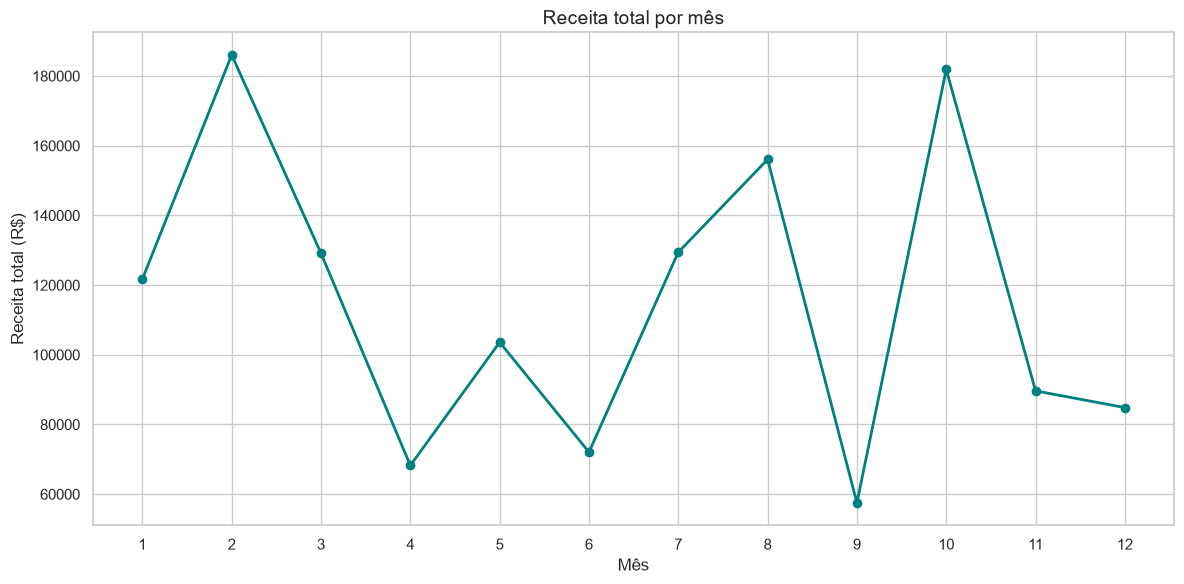

Gráfico salvo em: outputs/graficos/receita_por_mes.png


In [17]:
caminho_receita_mensal = gerar_grafico_receita_mensal(metricas)

print(f"Gráfico salvo em: {caminho_receita_mensal}")

In [18]:
# 2. Criar o gráfico dos cinco produtos com maior receita
def gerar_grafico_top_produtos(metricas, pasta_saida="outputs/graficos"):
    """
    Cria, salva e exibe o gráfico de barras dos cinco produtos com maior receita.
    """
    top_produtos = metricas["top_produtos"].copy()

    fig, ax = plt.subplots()

    sns.barplot(
        data=top_produtos, 
        x="receita_total", 
        y="produto", 
        hue="produto", 
        palette="Blues_d", 
        legend=False,  
        ax=ax
    )

    ax.set_title("Top 5 produtos por receita")
    ax.set_xlabel("Receita total (R$)")
    ax.set_ylabel("Produto")

    plt.tight_layout()

    os.makedirs(pasta_saida, exist_ok=True)
    caminho = f"{pasta_saida}/top_produtos.png"

    fig.savefig(caminho, dpi=150)
    plt.show()
    plt.close(fig)

    return caminho

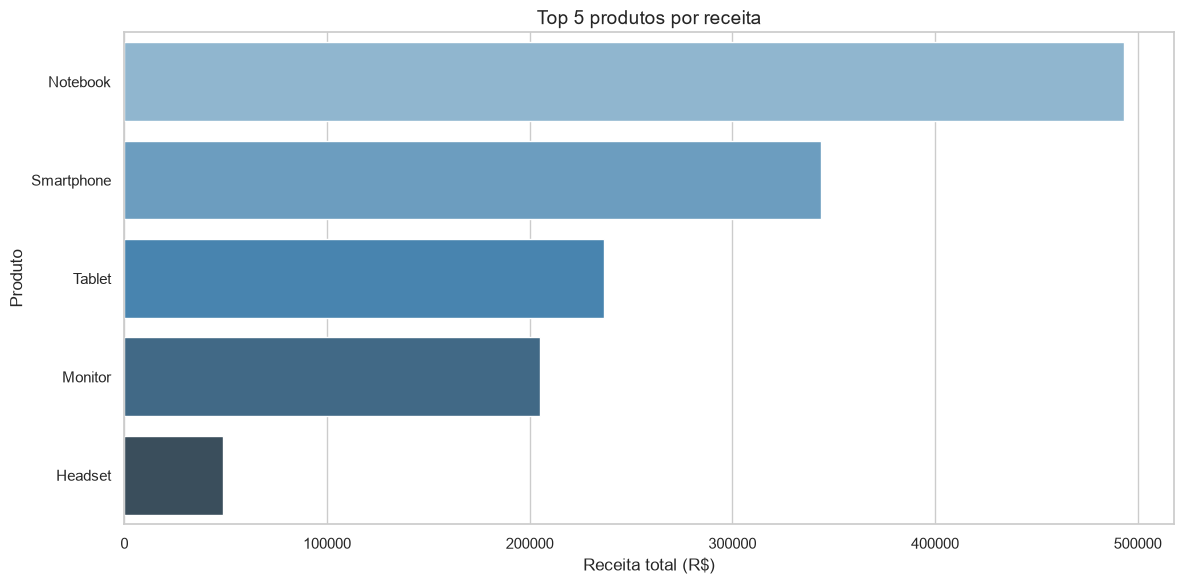

Gráfico salvo em: outputs/graficos/top_produtos.png


In [19]:
caminho_top_produtos = gerar_grafico_top_produtos(metricas)

print(f"Gráfico salvo em: {caminho_top_produtos}")

In [20]:
# 3. Criar o gráfico de dispersão por categoria
def criar_grafico_dispersao_categoria(df, pasta_saida="outputs/graficos"):
    """
    Cria, salva e exibe o gráfico de dispersão da quantidade vendida vs receita por venda.
    """

    fig, ax = plt.subplots()

    sns.scatterplot(
        data=df,
        x="quantidade",
        y="receita_total",
        hue="categoria",
        palette="Set2",
        ax=ax
    )

    ax.set_title("Quantidade vendida × receita total")
    ax.set_xlabel("Quantidade")
    ax.set_ylabel("Receita total (R$)")
    ax.legend(title="Categoria")

    plt.tight_layout()

    os.makedirs(pasta_saida, exist_ok=True)
    caminho = f"{pasta_saida}/quantidade_vs_receita.png"

    fig.savefig(caminho, dpi=150)
    plt.show()
    plt.close(fig)

    return caminho

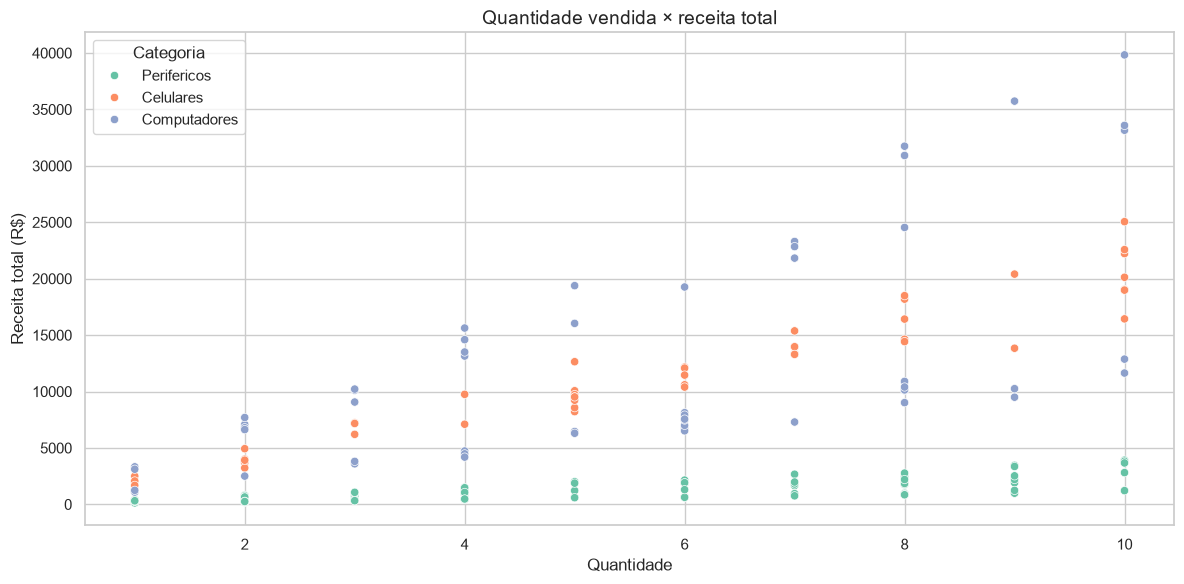

Gráfico salvo em: outputs/graficos/quantidade_vs_receita.png


In [21]:
caminho_dispersao = criar_grafico_dispersao_categoria(df)

print(f"Gráfico salvo em: {caminho_dispersao}")

In [22]:
# 4. Criar a estrutura do painel resumo
def criar_painel_resumo(df, metricas, pasta_saida="outputs/graficos"):
    """
    Cria, salva e exibe um painel resumo com 4 gráficos.
    """

    # Criar a estrutura do painel resumo
    fig, axes = plt.subplots(2, 2, figsize=(14, 9))
    fig.suptitle("SalesInsight PY - Painel resumo", fontsize=16)

    # Receita por mês (superior esquerdo)
    por_mes = metricas["por_mes"]

    axes[0, 0].plot(
        por_mes["mes"],
        por_mes["receita_total"],
        color="teal",
        marker="o",
        linewidth=2 
    )

    axes[0, 0].set_title("Receita por mês")
    axes[0, 0].set_xlabel("Mês")
    axes[0, 0].set_ylabel("Receita total (R$)")
    axes[0, 0].set_xticks(por_mes["mes"])


    # Top 5 produtos (superior direito)
    top_produtos = metricas["top_produtos"]

    sns.barplot(
        data=top_produtos,
        x="receita_total",
        y="produto",
        hue="produto",
        palette="Blues_d",
        legend=False,
        ax=axes[0, 1]
    )

    axes[0, 1].set_title("Top 5 produtos por receita")
    axes[0, 1].set_xlabel("Receita total (R$)")
    axes[0, 1].set_ylabel("Produto")


    # Quantidade × receita por categoria (inferior esquerdo)
    sns.scatterplot(
        data=df,
        x="quantidade",
        y="receita_total",
        hue="categoria",
        palette="Set2",
        ax=axes[1, 0]
    )

    axes[1, 0].set_title("Quantidade × receita por categoria")
    axes[1, 0].set_xlabel("Quantidade")
    axes[1, 0].set_ylabel("Receita total (R$)")
    axes[1, 0].legend(title="Categoria")


    # Receita por região (inferior direito)
    por_regiao = metricas["por_regiao"]

    sns.barplot(
        data=por_regiao,
        x="regiao",
        y="receita_total",
        hue="regiao",
        palette="Greens",
        legend=False,
        ax=axes[1, 1]
    )

    axes[1, 1].set_title("Receita por região")
    axes[1, 1].set_xlabel("Região")
    axes[1, 1].set_ylabel("Receita total (R$)")
    axes[1, 1].tick_params(axis="x", labelrotation=30)

    # Ajustar, salvar e exibir o painel completo
    plt.tight_layout()

    os.makedirs(pasta_saida, exist_ok=True)
    caminho = f"{pasta_saida}/painel_resumo.png"

    fig.savefig(caminho, dpi=150)
    plt.show()
    plt.close(fig)

    return caminho

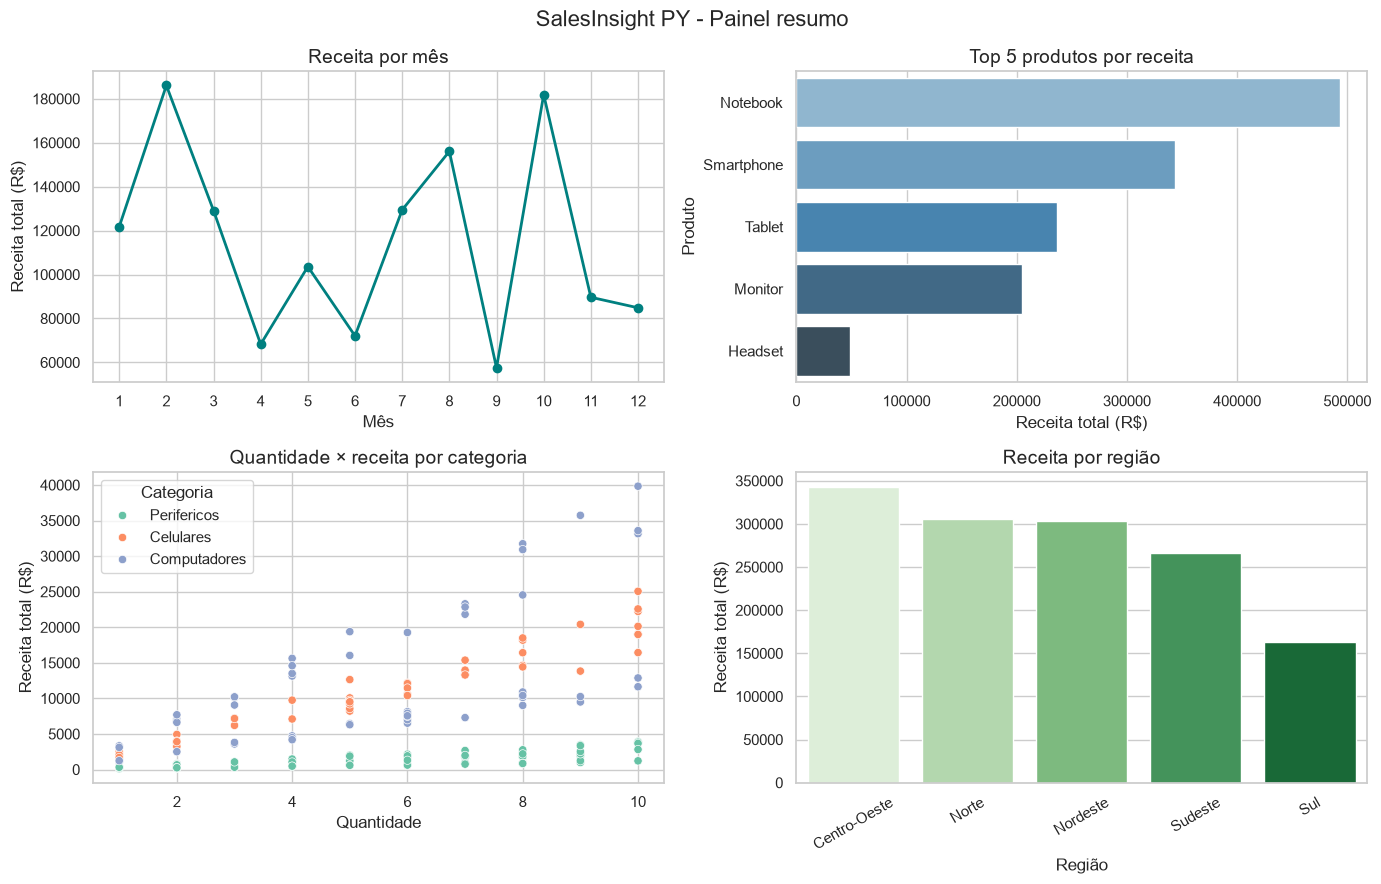

Painel salvo em: outputs/graficos/painel_resumo.png


In [23]:
caminho_painel = criar_painel_resumo(df, metricas)

print(f"Painel salvo em: {caminho_painel}")

## RF08 - Organizar o código em funções reutilizáveis

In [24]:
# Aplicar uma função de transformação a uma coluna
def processar_coluna(df, coluna, funcao_transformacao, nome_saida):
    """
    Aplica uma função aos valores de uma coluna do DataFrame.
    """

    df[nome_saida] = df[coluna].apply(funcao_transformacao)
    return df


# Criar colunas usando transformações numéricas e condicionais
def criar_colunas_adicionais(df):
    """
    Criar a receita em milhares e o perfil de volume das vendas.
    """

    df = df.copy()

    df = processar_coluna(
        df, 
        "receita_total",
        lambda receita: round(receita / 1000, 2),
        "receita_em_milhares"
    )

    df = processar_coluna(
        df,
        "quantidade",
        lambda quantidade: "Alto Volume" if quantidade > 5 else "Baixo Volume",
        "perfil_volume"
    )

    return df

In [25]:
df = criar_colunas_adicionais(df)

print(
    df[
        ["receita_total", "receita_em_milhares", "quantidade", "perfil_volume"]
    ].head().to_string(index=False)
)

 receita_total  receita_em_milhares  quantidade perfil_volume
        205.80                 0.21           2  Baixo Volume
      20405.97                20.41           9   Alto Volume
       4726.88                 4.73           4  Baixo Volume
        799.75                 0.80           7   Alto Volume
       6747.84                 6.75           2  Baixo Volume


## RF09 - Exportar resultados em CSV e JSON

In [26]:
import json

def exportar_resultados_csv(metricas, clientes, pasta_saida="outputs"):
    """
     Exporta as métricas mensais e a segmentação de clientes em CSV.
    """

    os.makedirs(pasta_saida, exist_ok=True)


    caminho_metricas = f"{pasta_saida}/metricas_por_mes.csv"
    caminho_clientes = f"{pasta_saida}/segmentacao_clientes.csv"

    metricas["por_mes"].to_csv(
        caminho_metricas,
        index=False,
        encoding="utf-8-sig"
    )

    clientes.to_csv(
        caminho_clientes,
        index=False,
        encoding="utf-8-sig"
    )

    caminhos = {
        "metricas_por_mes": caminho_metricas,
        "segmentacao_clientes": caminho_clientes
    }

    return caminhos

In [27]:
caminhos_csv = exportar_resultados_csv(metricas, clientes)

for nome, caminho in caminhos_csv.items():
    print(f"{nome}: {caminho}")

metricas_por_mes: outputs/metricas_por_mes.csv
segmentacao_clientes: outputs/segmentacao_clientes.csv


In [28]:
def calcular_estatisticas_gerais(df):
    """
    Calcula um resumo geral das vendas.
    """
    
    estatisticas = {
        "receita_total": round(float(df["receita_total"].sum()), 2),
        "ticket_medio": round(float(df["receita_total"].mean()), 2),
        "quantidade_vendida": int(df["quantidade"].sum()),
        "numero_vendas": len(df)
    }

    return estatisticas

In [29]:
estatisticas = calcular_estatisticas_gerais(df)

for nome, valor in estatisticas.items():
    print(f"{nome}: {valor}")

receita_total: 1380210.31
ticket_medio: 7114.49
quantidade_vendida: 1035
numero_vendas: 194


In [30]:
def exportar_estatisticas_json(estatisticas, pasta_saida="outputs"):
    """
    Grava as estatísticas gerais em JSON e lê o arquivo gerado.
    """
    
    os.makedirs(pasta_saida, exist_ok=True)
    caminho = f"{pasta_saida}/estatisticas_gerais.json"

    # Gravar o dicionário no arquivo JSON
    with open(caminho, "w", encoding="utf-8") as arquivo:
        json.dump(
            estatisticas,
            arquivo,
            indent=4,
            ensure_ascii=False
        )

    # Ler o arquivo para conferir o conteúdo gravado
    with open(caminho, "r", encoding="utf-8") as arquivo:
        conferencia = json.load(arquivo)

    return caminho, conferencia

In [31]:
caminho_json, conferencia = exportar_estatisticas_json(estatisticas)

print(f"JSON salvo em: {caminho_json}")
print("Conteúdo lido do arquivo:")

for nome, valor in conferencia.items():
    print(f"{nome}: {valor}")

JSON salvo em: outputs/estatisticas_gerais.json
Conteúdo lido do arquivo:
receita_total: 1380210.31
ticket_medio: 7114.49
quantidade_vendida: 1035
numero_vendas: 194
